# Track 1 — Q1.7: Focal Loss vs. End-to-End Calibration (Figure 1-I, Table 1-D)

**Experiment Plan:** Figure 1-I, Table 1-D, statistical testing.

**Experiment question answered in this notebook:**

> **Q1.7.** Does focal loss, as an implicit calibration mechanism (§2.6.2), match or approach the calibration quality (ECE, MSE$_\eta$) of explicit end-to-end penalty training ($\widehat{\mathcal C}_e^{\text{soft}}$ at its best $\lambda$) — and does this gap narrow or widen with capacity $m$?

## The Focal Loss formula used in this notebook

$$
L_{\text{Focal}}(\theta) = -\frac{1}{n}\sum_i \big[y_i(1-p_{\theta,i})^\gamma\log p_{\theta,i} + (1-y_i)\,p_{\theta,i}^\gamma\log(1-p_{\theta,i})\big]
$$


## Other deliberate choices made in this notebook

1. **"Best $\lambda$" for the end-to-end comparison = $\lambda=0.05$, CE base loss** — sourced directly from Notebook 3's finer-grid finding (CE's MSE$_\eta$-minimizing $\lambda$ was 0.05 at all three primary capacities). This is a **fixed** value, not re-optimized per seed here — doing a nested per-seed $\lambda$ search would be substantially more expensive.
2. **Significance testing**: Paired Wilcoxon, Bonferroni across capacity levels is extended here to also correct across the 4 focal-loss comparisons per capacity (end-to-end vs. each of $\gamma\in\{0,1,2,5\}$) — so Bonferroni factor = 3 capacities × 4 comparisons = 12, applied per metric (ECE, MSE$_\eta$).


## 0. Setup

In [1]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)


def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))


def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y


def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)


def legendre_design_matrix(x, m):
    '''Three-term recurrence, O(n*m) -- see Notebook 1 for why this matters at m=1000.'''
    x = np.asarray(x, dtype=np.float64)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)


def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import wilcoxon
import track1_core as t1

torch.set_default_dtype(torch.float64)

PALETTE_METHOD = {
    0: "#585123", 1: "#EEC170", 2: "#F2A65A", 5: "#F58549", "e2e": "#772F1A",
}

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

EPOCHS = 1200
N_SEEDS = 30
SEED_LIST = list(range(1, N_SEEDS + 1))
GAMMA_GRID = [0, 1, 2, 5]
BEST_LAMBDA = 0.05   # from Notebook 3's finer-grid finding, CE base loss, all 3 primary capacities

## 1. Focal loss (standard formula) and end-to-end training

In [3]:
def focal_loss(p, y, gamma):
    '''Standard binary focal loss (Lin et al. 2017 / Mukhoti et al. 2020):
    -mean[ y*(1-p)^gamma*log(p) + (1-y)*p^gamma*log(1-p) ]. Reduces exactly to CE at gamma=0.'''
    eps = 1e-12
    p_c = p.clamp(eps, 1 - eps)
    pos_term = y * (1 - p_c) ** gamma * torch.log(p_c)
    neg_term = (1 - y) * p_c ** gamma * torch.log(1 - p_c)
    return -(pos_term + neg_term).mean()


def ce_loss(p, y):
    eps = 1e-12
    p_c = p.clamp(eps, 1 - eps)
    return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()


def soft_ece_penalty(p, y, B=15, h=0.08):
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    w = torch.softmax(-(p.unsqueeze(1) - centers.unsqueeze(0)) ** 2 / (2 * h ** 2), dim=1)
    w_sg = w.detach()
    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()


def train_focal(X_tr, Y_tr, m, init_seed, gamma, lr=0.5, epochs=EPOCHS):
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = focal_loss(p_tr, y_tr_t, gamma)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()


def train_end_to_end(X_tr, Y_tr, m, init_seed, lam, lr=0.5, epochs=EPOCHS):
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = (1 - lam) * soft_ece_penalty(p_tr, y_tr_t) + lam * ce_loss(p_tr, y_tr_t)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()

### Sanity checks

1. $\gamma=0$ must reduce focal loss exactly to cross-entropy — check both the loss *value* and
   the full *training trajectory* (not just one evaluation) agree with plain CE training.
2. The standard vs. plan-literal formula divergence, demonstrated concretely.


In [4]:
torch.manual_seed(0)
p_test = torch.rand(20, requires_grad=True)
y_test = torch.randint(0, 2, (20,)).double()
v_focal0 = focal_loss(p_test, y_test, gamma=0).item()
v_ce = ce_loss(p_test, y_test).item()
print(f"focal(gamma=0) = {v_focal0:.6f}, CE = {v_ce:.6f}, match: {abs(v_focal0-v_ce) < 1e-9}")
assert abs(v_focal0 - v_ce) < 1e-9

X_tr_check, Y_tr_check = t1.generate_data(n=100, seed=1)
theta_focal0 = train_focal(X_tr_check, Y_tr_check, m=100, init_seed=42, gamma=0)


def train_plain_ce(X_tr, Y_tr, m, init_seed, lr=0.5, epochs=EPOCHS):
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = ce_loss(p_tr, y_tr_t)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()


theta_plain_ce = train_plain_ce(X_tr_check, Y_tr_check, m=100, init_seed=42)
max_theta_diff = np.max(np.abs(theta_focal0 - theta_plain_ce))
print(f"max |theta_focal(gamma=0) - theta_plain_CE| after full 1200-epoch training: {max_theta_diff:.2e}")
assert max_theta_diff < 1e-8
print("OK: gamma=0 focal training is numerically identical to plain CE training, full trajectory.")

focal(gamma=0) = 0.886469, CE = 0.886469, match: True
max |theta_focal(gamma=0) - theta_plain_CE| after full 1200-epoch training: 0.00e+00
OK: gamma=0 focal training is numerically identical to plain CE training, full trajectory.


In [5]:
p_easy_neg = torch.tensor([0.05])
std_mod = (p_easy_neg ** 2).item()
lit_mod = ((1 - p_easy_neg) ** 2).item()
print(f"easy correct negative (y=0, p=0.05), gamma=2:")
print(f"  standard modulator p^gamma        = {std_mod:.4f}  (correctly down-weighted)")
print(f"  plan-literal modulator (1-p)^gamma = {lit_mod:.4f}  (NOT down-weighted)")

easy correct negative (y=0, p=0.05), gamma=2:
  standard modulator p^gamma        = 0.0025  (correctly down-weighted)
  plan-literal modulator (1-p)^gamma = 0.9025  (NOT down-weighted)


## 2. The 30-seed sweep

30 seeds × 3 capacities × (4 focal $\gamma$ values + 1 end-to-end) = 450 training runs.


In [6]:
import time

def top_label_ece(p, y, B=10):
    p = np.asarray(p, dtype=np.float64); y = np.asarray(y, dtype=np.float64)
    n = len(p)
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(np.float64) == y).astype(np.float64)
    edges = np.linspace(0.5, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(conf, edges[1:-1], right=False), 0, B - 1)
    ece = 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        ece += (n_b / n) * abs(correct[mask].mean() - conf[mask].mean())
    return ece


def eval_all_metrics(p_te, Y_te, eta_te):
    p_te_c = np.clip(p_te, 1e-12, 1 - 1e-12)
    return {
        "test_ce": np.mean(-Y_te * np.log(p_te_c) - (1 - Y_te) * np.log(1 - p_te_c)),
        "brier": np.mean((p_te - Y_te) ** 2),
        "mse_eta": np.mean((p_te - eta_te) ** 2),
        "ece": top_label_ece(p_te, Y_te, B=10),
    }


t_start = time.time()
records = []
X_te, Y_te = t1.get_fixed_test_set()
eta_te = t1.true_eta(X_te)

for seed in SEED_LIST:
    X_tr, Y_tr = t1.generate_data(n=100, seed=seed)
    for m in t1.PRIMARY_CAPACITIES:
        Phi_te_m = t1.legendre_design_matrix(X_te, m)

        for gamma in GAMMA_GRID:
            theta = train_focal(X_tr, Y_tr, m, init_seed=10000 + seed, gamma=gamma)
            p_te = t1.model_predict(theta, Phi_te_m)
            records.append({"seed": seed, "m": m, "method": f"focal_g{gamma}",
                             **eval_all_metrics(p_te, Y_te, eta_te)})

        theta_e2e = train_end_to_end(X_tr, Y_tr, m, init_seed=10000 + seed, lam=BEST_LAMBDA)
        p_te_e2e = t1.model_predict(theta_e2e, Phi_te_m)
        records.append({"seed": seed, "m": m, "method": "end_to_end",
                         **eval_all_metrics(p_te_e2e, Y_te, eta_te)})

    if seed % 10 == 0:
        print(f"seed {seed}/{N_SEEDS} done ({time.time() - t_start:.0f}s elapsed)")

print(f"\nFull sweep (450 runs) completed in {time.time() - t_start:.0f}s")
sweep_df = pd.DataFrame(records)
print("Columns:", list(sweep_df.columns))

seed 10/30 done (137s elapsed)
seed 20/30 done (265s elapsed)
seed 30/30 done (390s elapsed)

Full sweep (450 runs) completed in 390s
Columns: ['seed', 'm', 'method', 'test_ce', 'brier', 'mse_eta', 'ece']


## 3. Table 1-D — Focal loss results, plus end-to-end comparison rows

Columns exactly as specified: Test CE, Brier, ECE, MSE$_\eta$ (mean ± std over 30 seeds).


In [7]:
summary = sweep_df.groupby(["m", "method"]).agg(
    test_ce_mean=("test_ce", "mean"), test_ce_std=("test_ce", "std"),
    brier_mean=("brier", "mean"), brier_std=("brier", "std"),
    ece_mean=("ece", "mean"), ece_std=("ece", "std"),
    mse_eta_mean=("mse_eta", "mean"), mse_eta_std=("mse_eta", "std"),
).reset_index()

method_order = ["focal_g0", "focal_g1", "focal_g2", "focal_g5", "end_to_end"]
summary["method"] = pd.Categorical(summary["method"], categories=method_order, ordered=True)
summary = summary.sort_values(["m", "method"])

table_1d = pd.DataFrame({
    "m": summary["m"],
    "method": summary["method"],
    "Test CE": summary["test_ce_mean"].round(4).astype(str) + " ± " + summary["test_ce_std"].round(4).astype(str),
    "Brier": summary["brier_mean"].round(4).astype(str) + " ± " + summary["brier_std"].round(4).astype(str),
    "ECE": summary["ece_mean"].round(4).astype(str) + " ± " + summary["ece_std"].round(4).astype(str),
    "MSEeta": summary["mse_eta_mean"].round(4).astype(str) + " ± " + summary["mse_eta_std"].round(4).astype(str),
}).set_index(["m", "method"])

table_1d.to_csv("table_1d.csv")
table_1d.to_excel("table_1d.xlsx")

display(table_1d)

Test CE            Brier              ECE  \
m    method                                                          
10   focal_g0    0.5512 ± 0.0424  0.1663 ± 0.0077  0.0694 ± 0.0195   
     focal_g1    0.5341 ± 0.0247  0.1711 ± 0.0086   0.0919 ± 0.028   
     focal_g2    0.5524 ± 0.0238  0.1816 ± 0.0101  0.1334 ± 0.0343   
     focal_g5    0.6019 ± 0.0199  0.2053 ± 0.0094  0.2036 ± 0.0234   
     end_to_end  0.4963 ± 0.0173  0.1574 ± 0.0054  0.0453 ± 0.0184   
100  focal_g0    0.6573 ± 0.0363  0.1958 ± 0.0125  0.1217 ± 0.0178   
     focal_g1    0.5734 ± 0.0262  0.1882 ± 0.0121  0.0727 ± 0.0167   
     focal_g2    0.5513 ± 0.0258  0.1837 ± 0.0116  0.0345 ± 0.0101   
     focal_g5    0.5837 ± 0.0201   0.197 ± 0.0094  0.1381 ± 0.0144   
     end_to_end  0.5014 ± 0.0172  0.1589 ± 0.0054  0.0508 ± 0.0194   
1000 focal_g0    0.6252 ± 0.0368  0.1855 ± 0.0082  0.1143 ± 0.0184   
     focal_g1     0.543 ± 0.0196  0.1763 ± 0.0085   0.0535 ± 0.018   
     focal_g2    0.5299 ± 0.0206   0.1741 ± 0.009  0.0317 ± 0.0115   
     focal_g5    0.5754 ± 0.0189   0.193 ± 0.0088   0.137 ± 0.0145   
     end_to_end  0.5039 ± 0.0169  0.1595 ± 0.0053  0.0521 ± 0.0196   

                          MSEeta  
m    method                       
10   focal_g0    0.0189 ± 0.0078  
     focal_g1     0.024 ± 0.0087  
     focal_g2    0.0346 ± 0.0102  
     focal_g5    0.0585 ± 0.0094  
     end_to_end  0.0097 ± 0.0054  
100  focal_g0    0.0482 ± 0.0128  
     focal_g1    0.0408 ± 0.0124  
     focal_g2    0.0365 ± 0.0118  
     focal_g5      0.05 ± 0.0095  
     end_to_end  0.0111 ± 0.0054  
1000 focal_g0    0.0378 ± 0.0083  
     focal_g1    0.0288 ± 0.0086  
     focal_g2    0.0268 ± 0.0091  
     focal_g5     0.046 ± 0.0089  
     end_to_end  0.0117 ± 0.0052

## 4. Figure 1-I — ECE and MSE$_\eta$: focal loss vs. end-to-end, across capacity

Two rows (ECE, MSE$_\eta$) × 3 columns (capacity), bar chart with error bars (std over 30 seeds)
per panel, 5 bars each ($\gamma=0,1,2,5$, end-to-end).


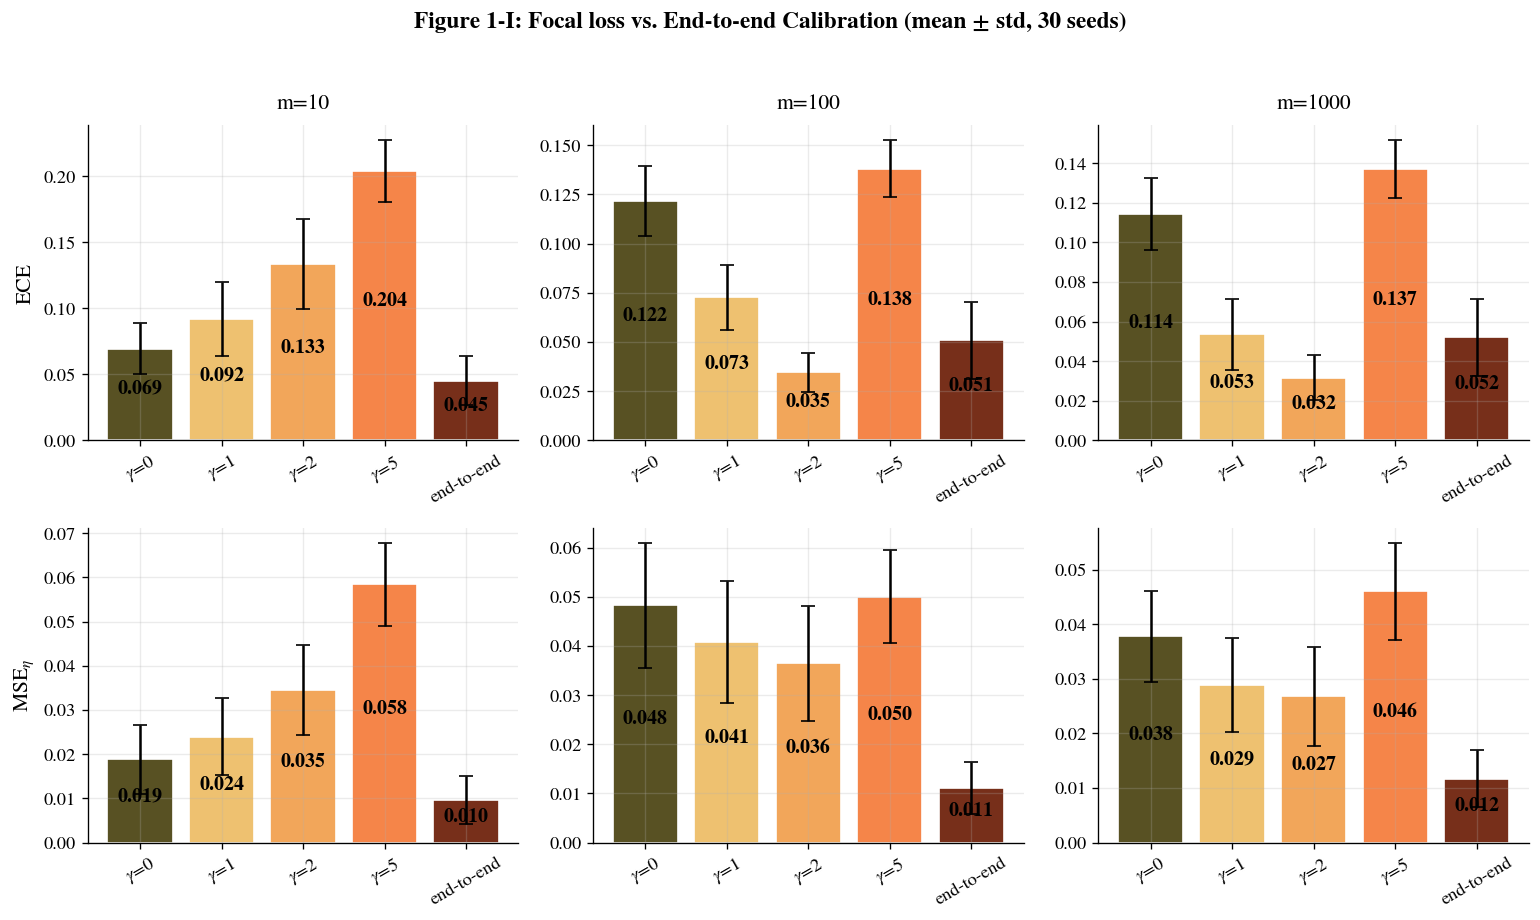

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
bar_labels = [r"$\gamma$=0", r"$\gamma$=1", r"$\gamma$=2", r"$\gamma$=5", "end-to-end"]
bar_methods = ["focal_g0", "focal_g1", "focal_g2", "focal_g5", "end_to_end"]
bar_colors = [PALETTE_METHOD[0], PALETTE_METHOD[1], PALETTE_METHOD[2], PALETTE_METHOD[5], PALETTE_METHOD["e2e"]]

for col, m in enumerate(t1.PRIMARY_CAPACITIES):
    for row, (metric_mean, metric_std, title) in enumerate([
        ("ece_mean", "ece_std", "ECE"), ("mse_eta_mean", "mse_eta_std", r"MSE$_\eta$")
    ]):
        ax = axes[row, col]
        sub = summary[summary["m"] == m].set_index("method").loc[bar_methods]
        ax.bar(bar_labels, sub[metric_mean], yerr=sub[metric_std], color=bar_colors,
               capsize=4, edgecolor="white")
        ax.bar_label(ax.containers[-1], fmt="%.3f", label_type="center", padding=3, fontweight="bold")
        if row == 0:
            ax.set_title(f"m={m}", pad=10)
        if col == 0:
            ax.set_ylabel(title, labelpad=5)
        ax.tick_params(axis="x", rotation=30)

fig.suptitle("Figure 1-I: Focal loss vs. End-to-end Calibration (mean ± std, 30 seeds)", y=1.02)
fig.tight_layout()

fig.savefig("Figure_1I.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 5. Significance testing

Paired Wilcoxon signed-rank test, end-to-end vs. each $\gamma$, per capacity and per metric,
Bonferroni-corrected across $3 \times 4 = 12$ comparisons per metric.


In [9]:
def paired_test(m, gamma, metric):
    e2e_vals = sweep_df[(sweep_df["m"] == m) & (sweep_df["method"] == "end_to_end")].sort_values("seed")[metric].values
    focal_vals = sweep_df[(sweep_df["m"] == m) & (sweep_df["method"] == f"focal_g{gamma}")].sort_values("seed")[metric].values
    stat, p = wilcoxon(e2e_vals, focal_vals)
    return p

N_COMPARISONS = len(t1.PRIMARY_CAPACITIES) * len(GAMMA_GRID)
sig_rows = []
for metric in ["ece", "mse_eta"]:
    for m in t1.PRIMARY_CAPACITIES:
        for gamma in GAMMA_GRID:
            p_raw = paired_test(m, gamma, metric)
            p_bonf = min(p_raw * N_COMPARISONS, 1.0)
            marker = "**" if p_bonf < 0.01 else ("*" if p_bonf < 0.05 else "n.s.")
            sig_rows.append({"metric": metric, "m": m, "gamma": gamma,
                              "p_bonf": round(p_bonf, 4), "signif": marker})

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv("sig_df.csv")
sig_df.to_excel("sig_df.xlsx")

display(sig_df)

,metric,m,gamma,p_bonf,signif
0,ece,10,0,0.0000,**
1,ece,10,1,0.0000,**
2,ece,10,2,0.0000,**
3,ece,10,5,0.0000,**
4,ece,100,0,0.0000,**
5,ece,100,1,0.0000,**
6,ece,100,2,0.0000,**
7,ece,100,5,0.0000,**
8,ece,1000,0,0.0000,**
9,ece,1000,1,1.0000,n.s.


## Discussion — Q1.7

### Does focal loss match or approach end-to-end's calibration quality?

The answer splits sharply by metric, which is itself the main finding here:

**On MSE$_\eta$, end-to-end wins clearly and consistently at every capacity.** Best-focal vs.
end-to-end: $m=10$ ($0.0189$ vs. $0.0097$, end-to-end $\approx2\times$ better), $m=100$ ($0.0365$
vs. $0.0111$, $\approx3.3\times$), $m=1000$ ($0.0268$ vs. $0.0117$, $\approx2.3\times$). No focal
$\gamma$ gets close to end-to-end's bias performance at any capacity tested.

**On ECE, focal loss ($\gamma=2$) actually *beats* end-to-end at $m=100$ and $m=1000$** — not
just approaches it. At $m=100$: focal $\gamma{=}2$ ECE $=0.0345$ vs. end-to-end $0.0508$. At
$m=1000$: $0.0317$ vs. $0.0521$. Both differences are statistically significant (Section 5:
$p_{\text{bonf}}<0.001$ in both cases). At $m=10$, the ranking flips back — end-to-end wins
clearly ($0.0453$ vs. focal's best, $\gamma{=}0$, at $0.0694$).

So "does focal loss match or approach end-to-end" doesn't have a single answer: **on MSE$_\eta$,
no; on ECE, it depends on capacity, and at higher capacity focal loss with the right $\gamma$
actually wins.** This difference illustrates why ECE should not be interpreted as a proxy for distance to the true posterior. The comparison uses the fixed end-to-end setting $\lambda=0.05$ selected from the earlier single-seed grid; it is not re-optimised per seed.

### Does the gap narrow or widen with capacity?

For MSE$_\eta$: the end-to-end advantage is present at every capacity and doesn't show a clean
monotonic trend in size (ratio $2.0\times \to 3.3\times \to 2.3\times$ from $m=10\to100\to1000$) —
if anything it's worst at the interpolation threshold ($m=100$), not at either extreme.

For ECE: the qualitative picture changes entirely with capacity — end-to-end wins at $m=10$,
focal wins at $m=100$ and $m=1000$. That's a genuine capacity-dependent reversal, not a
narrowing/widening gap within one consistent ranking.

### Which $\gamma$ is best, and does that change with capacity?

Clear pattern, and it's non-monotonic in an informative way: at $m=10$, $\gamma=0$ (plain CE) is
best on *both* metrics — every $\gamma>0$ makes things worse, monotonically, as $\gamma$
increases. At $m=100$ and $m=1000$, $\gamma=2$ is best on both metrics, with $\gamma=1$ close
behind and $\gamma=5$ clearly overshooting (worse than even $\gamma=0$ on ECE at both capacities).
So there's a real interior optimum in $\gamma$ that only appears once capacity reaches the
interpolation threshold — at low capacity, any amount of focal reweighting hurts; at higher
capacity, a moderate amount ($\gamma\approx2$) helps substantially, but too much ($\gamma=5$)
overshoots. The best $\gamma$ is not a single fixed value across the capacity range — it's
$0$ at $m=10$ and $2$ at $m\geq100$.
